# Decision tree and random forest vs. the linear baseline

**IDX Exchange | Week 5**

Do tree models price California single-family homes more accurately than the Week 4 linear regressions when given the same six inputs? Everything except the model is held fixed: the same cleaned sales (snapshot `2ff3877a04bd`), the same chronological split, tuning on February 2026 only, and the same three earlier monthly cutoffs as a check. March 2026 is not used.

A random forest (200 trees, log-price target, target-encoded city and ZIP) reaches **9.5%** February MdAPE, against 16.8% for linear regression and 10.6% for log-log linear regression. The paired-bootstrap 95% interval for its gain over log-log OLS is 0.9 to 1.4 points, and it had the lowest MdAPE at all four cutoffs (9.3–9.5%). A single tuned decision tree (10.6%) is statistically tied with log-log OLS.

On the March 2026 test, scored once after the selection was locked, the forest reaches 9.2% MdAPE against 16.6% for linear regression and 10.0% for log-log OLS. Its lead over log-log OLS narrows from 1.1 points in February to 0.9, and the single tree falls behind log-log OLS (10.4%). Including the 1.2% of March sales outside the price bounds, the forest's R² (0.628) is below log-log OLS (0.698).

Recommendation: carry the random forest forward as the model to beat in Weeks 6–7, with log-log OLS as the linear reference.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from matplotlib.ticker import FuncFormatter, NullFormatter
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer

sys.path.insert(0, str(Path("../src").resolve()))
import avm  # noqa: E402

DATA_DIR = Path("../data/raw")
RESULTS_DIR = Path("../results")
MODELS_DIR = Path("../models")
TARGET = avm.TARGET
VAL_MONTH, TEST_MONTH = avm.VAL_MONTH, avm.TEST_MONTH
RANDOM_STATE = avm.RANDOM_STATE

# Week 4 reference values: the data pull and cleaned row count must match 03.
EXPECTED_FINGERPRINT = "2ff3877a04bd"
EXPECTED_CLEAN_ROWS = 297_152

# Model selection is locked (commit 61bcbdb): the tuning grid and the backtests are
# loaded from the saved results instead of being refit. Set these to True to rebuild them.
RETUNE = False
RERUN_BACKTESTS = False
# The February choices are final, so March is scored once.
RUN_FINAL_TEST = True

DT_GRID = {"max_depth": [6, 10, 14, 18, None], "min_samples_leaf": [5, 20, 50]}
RF_GRID = {"n_estimators": [200, 400], "max_features": [0.33, 0.5, 1.0],
           "min_samples_leaf": [1, 5, 10], "max_depth": [None]}
N_BOOTSTRAP = 1_000
IMPORTANCE_SAMPLE = 5_000

LINEAR, LOG_LINEAR = "Linear regression", "Log-log linear regression"
TREE, FOREST = "Decision tree", "Random forest"
SHORT_NAMES = {LINEAR: "Linear", LOG_LINEAR: "Log-log", TREE: "Tree", FOREST: "Forest"}
MODEL_COLORS = {LINEAR: "#9a9a9a", LOG_LINEAR: "#3b6ea8", TREE: "#e08a2e", FOREST: "#2f8f5b"}
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| joblib", joblib.__version__)

pandas 3.0.6 | numpy 2.5.3 | sklearn 1.9.1 | joblib 1.6.0


## 2. Data and Week 4 reproduction

Loading and cleaning now live in `src/avm.py`, which ports the notebook 03 logic unchanged. Three asserts stop the notebook if anything has drifted: the data-snapshot fingerprint, the cleaned row count, and the February MdAPE of both linear models against `results/baseline_metrics.csv`. If they pass, any difference below comes from the model, not the data.

In [2]:
raw, snapshot, fingerprint = avm.load_raw(DATA_DIR)
df, cleaning_steps, set_missing = avm.clean(raw)
assert fingerprint == EXPECTED_FINGERPRINT, f"Data pull changed: {fingerprint}"
assert len(df) == EXPECTED_CLEAN_ROWS, f"Cleaning changed: {len(df):,} rows"

months = sorted(df["CloseMonth"].unique())
assert months[-1] == TEST_MONTH and VAL_MONTH in months
assert set(avm.BACKTEST_MONTHS) < set(months) and TEST_MONTH not in avm.BACKTEST_MONTHS

baseline_metrics = pd.read_csv(RESULTS_DIR / "baseline_metrics.csv", dtype={"month": str})
linear_check = avm.run_cutoff(df, VAL_MONTH, avm.LINEAR_MODELS)
for name, res in linear_check["results"].items():
    for scope in ("filtered", "all"):
        saved = baseline_metrics.query(
            "split == 'validation' and model == @name and scope == @scope")["MdAPE_pct"].item()
        assert round(res[scope]["MdAPE_pct"], 3) == round(saved, 3), (name, scope)

print(f"Snapshot {fingerprint}: {len(raw):,} raw rows, {len(df):,} after cleaning")
print(f"Training months for February: {linear_check['train_months'][0]}–"
      f"{linear_check['train_months'][1]} ({linear_check['n_train']:,} sales after price filter)")
print("Week 4 February MdAPE reproduced:",
      {name: round(res["filtered"]["MdAPE_pct"], 3) for name, res in linear_check["results"].items()})

Snapshot 2ff3877a04bd: 591,446 raw rows, 297,152 after cleaning
Training months for February: 202401–202601 (273,904 sales after price filter)
Week 4 February MdAPE reproduced: {'Linear regression': np.float64(16.804), 'Log-log linear regression': np.float64(10.594)}


## 3. Tree preprocessing

The tree models use the same six inputs as Week 4 but a different preprocessing pipeline, built by `avm.make_tree_model` and fitted inside each cutoff's training data:

- **No scaling.** A split compares one feature to a threshold, so rescaling a feature does not change which splits are possible. For the same reason the trees do not need the log transform on living area and lot size.
- **Numeric fields:** median imputation with missing-value indicators, as in Week 4. The indicator lets a tree route a missing value separately instead of treating it as a median-sized home.
- **City and ZIP:** the Week 4 one-hot encoding produces several thousand sparse columns. A tree can only split on one of them at a time, so most ZIPs would rarely be used. Instead each category is replaced by its smoothed mean training price with sklearn's `TargetEncoder`. During fitting the encoder is cross-fitted over 5 seeded folds, so a sale's encoding is computed without its own price. That is the CV-safe target encoding the best-practices document requires. Missing values become an explicit `UNKNOWN` category, and categories never seen in training receive the overall training mean.
- **Target:** each tree is tuned on raw price and on log price (`TransformedTargetRegressor` with `np.log`/`np.exp`). With a log target, squared-error splits weigh a $50K miss on a $300K home more heavily than on a $3M home, which matches a percentage-error metric.

## 4. Tuning on February

Every configuration is trained on all sales from January 2024 to January 2026 that fall inside the training-derived price bounds, and scored on February's filtered sales. The grids are shown to two decimals because neighbouring configurations often differ by less than 0.1 points. Every configuration and its fit time are in `results/tuning_grid.csv`. Since the selection was locked, the notebook loads that file instead of refitting the 66 configurations (about 19 minutes); set `RETUNE = True` to rebuild it.

The selection rule is the lowest February MdAPE, with configurations within 0.1 points of the best treated as tied and the simplest of those chosen. For the forest, that means fewer trees and then larger leaves; for the tree, larger leaves and then shallower depth. The tolerance was added after a first run. The strict winner (400 trees, no leaf limit, 9.44%) needed several GB of memory and saved as a 2.2 GB file, and its 0.03-point edge is far inside the bootstrap noise measured in section 6.

In [3]:
if RETUNE:
    tuning = pd.concat([
        avm.run_grid(df, VAL_MONTH, TREE, DT_GRID, score_train=True),
        avm.run_grid(df, VAL_MONTH, FOREST, RF_GRID),
    ], ignore_index=True)
    tuning.to_csv(RESULTS_DIR / "tuning_grid.csv", index=False)
else:
    tuning = pd.read_csv(RESULTS_DIR / "tuning_grid.csv")
print(f"{len(tuning)} configurations ({'refit' if RETUNE else 'loaded from tuning_grid.csv'})")

fit_time = tuning.groupby("model")["fit_seconds"].agg(["min", "max", "sum"])
for model, row in fit_time.iterrows():
    print(f"{model}: {row['min']:.1f}–{row['max']:.1f} s per fit, "
          f"{row['sum'] / 60:.1f} min for the grid")

66 configurations (loaded from tuning_grid.csv)
Decision tree: 0.4–0.9 s per fit, 0.3 min for the grid
Random forest: 6.5–71.7 s per fit, 18.5 min for the grid


In [4]:
def grid_view(model, index):
    """Validation MdAPE (%) for every grid point of one model, two decimals."""
    subset = tuning.loc[tuning["model"] == model].copy()
    for col in index:
        subset[col] = subset[col].map(lambda v: "None" if pd.isna(v) else f"{v:g}")
    view = subset.pivot_table(index=index, columns=["target", "min_samples_leaf"],
                              values="MdAPE_pct", sort=False)
    view.columns = view.columns.set_levels(view.columns.levels[1].astype(int), level=1)
    view.columns.names = ["Target", "Min samples per leaf"]
    return view.map("{:.2f}".format)

print("Decision tree: February MdAPE (%)")
display(grid_view(TREE, ["max_depth"]))
print("Random forest: February MdAPE (%)")
display(grid_view(FOREST, ["n_estimators", "max_features"]))

Decision tree: February MdAPE (%)


Target                price               log price              
Min samples per leaf     5      20     50        5      20     50
max_depth                                                        
6                     14.61  14.61  14.61     13.45  13.45  13.45
10                    12.04  12.00  11.98     11.72  11.64  11.61
14                    11.01  11.04  11.16     10.66  10.86  10.79
18                    10.80  10.60  10.99     10.61  10.68  10.55
None                  11.48  10.70  10.93     11.27  10.58  10.60

Random forest: February MdAPE (%)


Target                    price               log price            
Min samples per leaf         1      5      10        1     5     10
n_estimators max_features                                          
200          0.33          9.80  10.13  10.37      9.53  9.75  9.98
             0.5           9.70   9.83   9.99      9.52  9.47  9.62
             1             9.84   9.80   9.91      9.74  9.56  9.62
400          0.33          9.81  10.08  10.37      9.48  9.67  9.94
             0.5           9.69   9.80  10.00      9.44  9.47  9.57
             1             9.76   9.77   9.84      9.71  9.55  9.60

Lowest MdAPE in each grid: {'Decision tree': '10.55% (max_depth=18, min_samples_leaf=50, target=log price)', 'Random forest': '9.44% (n_estimators=400, max_features=0.5, min_samples_leaf=1, max_depth=None, target=log price)'}


,Selected configuration,Fit time (s),R²,MdAPE (%)
model,,,,
Decision tree,"max_depth=18, min_samples_leaf=50, target=log price",0.7,0.834,10.6
Random forest,"n_estimators=200, max_features=0.5, min_samples_leaf=5, max_depth=None, target=log price",14.0,0.859,9.5


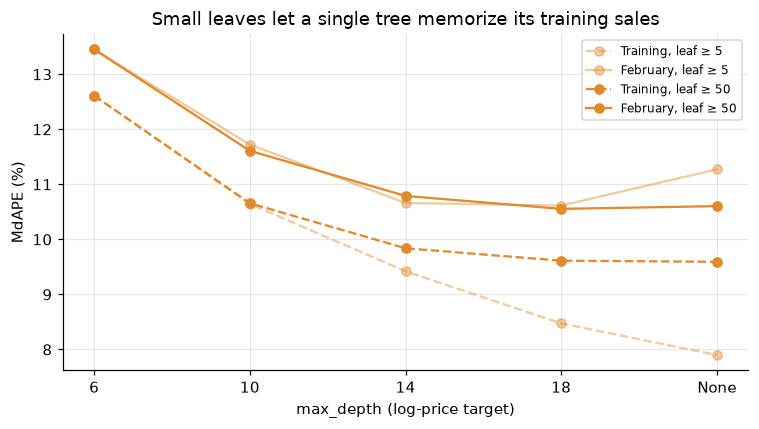

In [5]:
# Configurations within this many MdAPE points of the best are treated as tied:
# the paired-bootstrap intervals in section 6 are roughly ±0.3 points wide.
TOLERANCE = 0.1
SIMPLEST_FIRST = {TREE: (["min_samples_leaf", "max_depth"], [False, True]),
                  FOREST: (["n_estimators", "min_samples_leaf"], [True, False])}

def select(model):
    """Simplest configuration within TOLERANCE of the lowest February MdAPE."""
    rows = tuning.loc[tuning["model"] == model]
    near_best = rows.loc[rows["MdAPE_pct"] <= rows["MdAPE_pct"].min() + TOLERANCE]
    columns, ascending = SIMPLEST_FIRST[model]
    return near_best.sort_values(columns + ["MdAPE_pct"], ascending=ascending + [True]).iloc[0]

best = pd.DataFrame([select(TREE), select(FOREST)]).set_index("model")
best_overall = tuning.loc[tuning.groupby("model")["MdAPE_pct"].idxmin()].set_index("model")
print("Lowest MdAPE in each grid:",
      {model: f"{row['MdAPE_pct']:.2f}% ({row['params']})" for model, row in best_overall.iterrows()})
display(avm.format_table(best[["params", "fit_seconds", "R2", "MdAPE_pct"]])
        .rename(columns={"params": "Selected configuration", "fit_seconds": "Fit time (s)"})
        .assign(**{"Fit time (s)": best["fit_seconds"].map("{:.1f}".format)}))

fig, ax = plt.subplots()
for leaf, alpha in [(5, 0.45), (50, 1.0)]:
    curve = tuning.loc[(tuning["model"] == TREE) & (tuning["target"] == best.loc[TREE, "target"])
                       & (tuning["min_samples_leaf"] == leaf)]
    depth_labels = curve["max_depth"].map(lambda d: "None" if pd.isna(d) else f"{d:g}")
    ax.plot(depth_labels, curve["train_MdAPE_pct"], marker="o", linestyle="--", alpha=alpha,
            color=MODEL_COLORS[TREE], label=f"Training, leaf ≥ {leaf}")
    ax.plot(depth_labels, curve["MdAPE_pct"], marker="o", alpha=alpha,
            color=MODEL_COLORS[TREE], label=f"February, leaf ≥ {leaf}")
ax.set(xlabel="max_depth (log-price target)", ylabel="MdAPE (%)",
       title="Small leaves let a single tree memorize its training sales")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The log-price target is better in all 18 forest settings and 14 of 15 tree settings, so both selected models use it. For the forest, `max_features=0.5` is best at every leaf size; the number of trees barely matters. The selected forest (200 trees, at least 5 sales per leaf, 9.47%) fits in about 14 seconds. The strict winner took about three times as long.

The chart shows why the tree needs a large minimum leaf. With at least 5 sales per leaf and no depth limit, training MdAPE keeps falling (7.9%) while February MdAPE rises to 11.3%. Requiring 50 sales per leaf keeps the gap near 1 point and gives the best single tree (depth 18, 10.55%), which the tolerance rule also selects.

## 5. Chosen configurations and overfitting

The selected settings are frozen in `FINAL_CONFIGS`, and an assert ties them to the grid selection so the dictionary cannot drift from the evidence. Each model is refit on the February training window and also scored on its own training sales. A tree with no depth or leaf limit is included for reference only.

Training predictions use the encoder's full-data encodings, while the trees were fitted on cross-fitted encodings, so in-sample fit is not exact. This likely explains why the unrestricted tree reaches 1.0% training MdAPE but only 0.903 training R²: a minority of sales land in a different leaf at prediction time.

In [6]:
FINAL_CONFIGS = {
    "Decision tree": {"params": {"max_depth": 18, "min_samples_leaf": 50},
                      "log_target": True},
    "Random forest": {"params": {"n_estimators": 200, "max_features": 0.5,
                                 "min_samples_leaf": 5, "max_depth": None},
                      "log_target": True},
}
for kind, config in FINAL_CONFIGS.items():
    assert avm.describe_config(config["params"], config["log_target"]) == best.loc[kind, "params"], kind

PARAMS = {LINEAR: "Week 4 specification", LOG_LINEAR: "Week 4 specification",
          **{kind: avm.describe_config(c["params"], c["log_target"]) for kind, c in FINAL_CONFIGS.items()}}
final_factories = {**avm.LINEAR_MODELS,
                   **{kind: avm.tree_factory(kind, c["params"], c["log_target"])
                      for kind, c in FINAL_CONFIGS.items()}}
MODEL_NAMES = list(final_factories)

val = avm.run_cutoff(df, VAL_MONTH, final_factories, score_train=True, keep_models=True)
# Reference only: a tree grown until every leaf holds a single sale.
unrestricted = avm.run_cutoff(
    df, VAL_MONTH,
    {"Decision tree, no limits": avm.tree_factory(TREE, {"max_depth": None, "min_samples_leaf": 1},
                                                  FINAL_CONFIGS[TREE]["log_target"])},
    score_train=True)

fit_check = pd.DataFrame({
    name: {"train_MdAPE_pct": res["train"]["MdAPE_pct"], "MdAPE_pct": res["filtered"]["MdAPE_pct"],
           "train_R2": res["train"]["R2"], "R2": res["filtered"]["R2"]}
    for name, res in {**val["results"], **unrestricted["results"]}.items()
}).T
fit_check.insert(2, "gap_pct", fit_check["MdAPE_pct"] - fit_check["train_MdAPE_pct"])
display(avm.format_table(fit_check).rename(columns={
    "train_MdAPE_pct": "Train MdAPE (%)", "MdAPE (%)": "Feb MdAPE (%)",
    "gap_pct": "Gap (points)", "train_R2": "Train R²", "R²": "Feb R²"}))

,Train MdAPE (%),Feb MdAPE (%),Gap (points),Train R²,Feb R²
Linear regression,15.9,16.8,0.9,0.828,0.811
Log-log linear regression,9.7,10.6,0.9,0.854,0.832
Decision tree,9.6,10.6,0.9,0.859,0.834
Random forest,7.4,9.5,2.0,0.905,0.859
"Decision tree, no limits",1.0,12.6,11.6,0.903,0.750


The unrestricted tree is the clearest case of overfitting: 1.0% MdAPE on its training sales and 12.6% in February, worse than both the tuned tree and log-log OLS. The forest also fits its training sales more closely than February (7.4% vs 9.5%), but averaging 200 decorrelated trees keeps most of that variance out of the validation error, and it still has the lowest February MdAPE. The linear models and the tuned tree have gaps under 1 point.

In [7]:
SUMMARY_COLUMNS = ["R2", "MAE_USD", "RMSE_USD", "MAPE_pct", "MdAPE_pct",
                   "PPE10_pct", "PPE20_pct", "median_bias_pct", "N"]
print(f"February 2026, filtered (training-derived bounds ${val['lower']:,.0f}–${val['upper']:,.0f}, "
      f"coverage {val['coverage']:.1%})")
display(avm.format_table(avm.metrics_table(val, "filtered", SUMMARY_COLUMNS)))
print("February 2026, all valid sales")
display(avm.format_table(avm.metrics_table(val, "all", SUMMARY_COLUMNS)))

February 2026, filtered (training-derived bounds $190,000–$8,287,751, coverage 99.0%)


,R²,MAE ($),RMSE ($),MAPE (%),MdAPE (%),Within 10% (%),Within 20% (%),Median bias (%),N
Linear regression,0.811,"247,365","425,290",23.3,16.8,31.1,57.5,-0.8,"8,869"
Log-log linear regression,0.832,"193,244","400,938",14.7,10.6,47.8,76.9,-0.5,"8,869"
Decision tree,0.834,"199,599","398,383",15.1,10.6,48.2,74.8,-0.1,"8,869"
Random forest,0.859,"181,860","367,288",13.7,9.5,52.0,78.5,-0.3,"8,869"


February 2026, all valid sales


,R²,MAE ($),RMSE ($),MAPE (%),MdAPE (%),Within 10% (%),Within 20% (%),Median bias (%),N
Linear regression,0.655,"282,249","780,666",25.2,17.0,30.8,57.0,-0.9,"8,958"
Log-log linear regression,0.711,"225,303","714,862",16.5,10.7,47.3,76.2,-0.5,"8,958"
Decision tree,0.665,"234,686","768,949",17.4,10.7,47.7,74.1,-0.0,"8,958"
Random forest,0.683,"216,681","748,217",15.9,9.6,51.5,77.8,-0.3,"8,958"


On filtered February sales the forest leads on every metric: MdAPE 9.5% vs 10.6% for log-log OLS, 52.0% of sales within 10% (vs 47.8%), and R² 0.859 (vs 0.832). The tuned tree matches log-log OLS on MdAPE and R² but has a higher MAPE (15.1% vs 14.7%) and fewer sales within 20% (74.8% vs 76.9%).

When the 1% of sales outside the price bounds are included, R² falls for every model and the forest (0.683) drops below log-log OLS (0.711). Trees cannot predict above the highest training price, which section 7 examines. Forest MdAPE barely moves (9.6%).

## 6. Does the gain hold up?

There are two checks. First, the chosen configurations are scored at the three earlier cutoffs from Week 4 (November 2025 to January 2026), each trained on all prior months. Those metrics are loaded from `results/model_comparison_metrics.csv`, with an assert that they were produced by the frozen configurations; set `RERUN_BACKTESTS = True` to refit them. Second, a paired bootstrap on February draws 1,000 resamples of the filtered sales (seed 42) and scores both models on the same resample each time. The result is a 95% interval for the difference in MdAPE.

MdAPE (%) by cutoff, filtered scope


month,202511,202512,202601,202602,Range (points)
model,,,,,
Linear regression,16.5,16.8,17.1,16.8,0.6
Log-log linear regression,10.0,10.1,10.6,10.6,0.6
Decision tree,10.3,10.4,10.3,10.6,0.2
Random forest,9.3,9.3,9.3,9.5,0.2


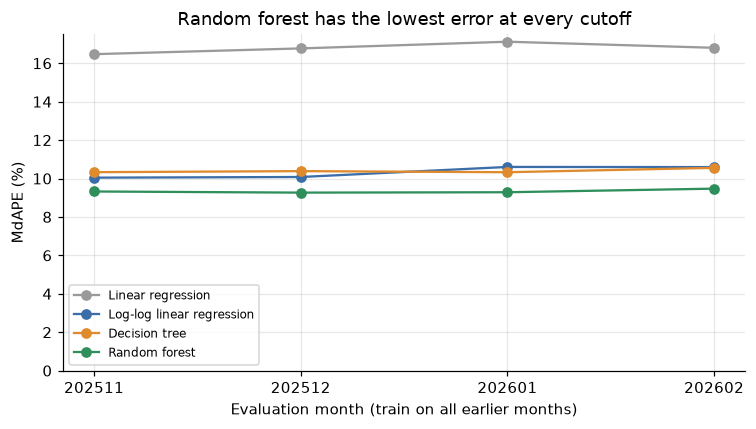

In [8]:
if RERUN_BACKTESTS:
    backtest_metrics = pd.DataFrame([
        row for month in avm.BACKTEST_MONTHS
        for row in avm.metric_records(avm.run_cutoff(df, month, final_factories), PARAMS)])
else:
    backtest_metrics = (pd.read_csv(RESULTS_DIR / "model_comparison_metrics.csv", dtype={"month": str})
                        .query("split == 'backtest'").reset_index(drop=True))
    cached_params = backtest_metrics.drop_duplicates("model").set_index("model")["params"].to_dict()
    assert cached_params == PARAMS, "Cached backtests were run with different configurations"
assert sorted(backtest_metrics["month"].unique()) == avm.BACKTEST_MONTHS
runs = {VAL_MONTH: val}

by_month = pd.concat([
    backtest_metrics.query("scope == 'filtered'")[["month", "model", "MdAPE_pct", "R2"]],
    pd.DataFrame([{"month": VAL_MONTH, "model": name, "MdAPE_pct": res["filtered"]["MdAPE_pct"],
                   "R2": res["filtered"]["R2"]} for name, res in val["results"].items()]),
])
stability = by_month.pivot(index="model", columns="month", values="MdAPE_pct").loc[MODEL_NAMES]
stability["range_pct"] = stability.max(axis=1) - stability.min(axis=1)
print("MdAPE (%) by cutoff, filtered scope")
display(stability.map("{:.1f}".format).rename(columns={"range_pct": "Range (points)"}))

fig, ax = plt.subplots()
for name in MODEL_NAMES:
    series = stability.loc[name, avm.BACKTEST_MONTHS + [VAL_MONTH]]
    ax.plot(series.index, series.values, marker="o", color=MODEL_COLORS[name], label=name)
ax.set(xlabel="Evaluation month (train on all earlier months)", ylabel="MdAPE (%)",
       title="Random forest has the lowest error at every cutoff", ylim=(0, None))
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

The forest has the lowest MdAPE at every cutoff (9.3–9.5%) and, with the single tree, the smallest spread across months (0.2 points). Log-log OLS ranges from 10.0% to 10.6%. The single tree beats log-log OLS in January (10.3% vs 10.6%) but loses in November and December, so the two are effectively tied.

In [9]:
in_range = val["in_range"]
y_val = val["evaluate"].loc[in_range, TARGET]
best_tree = min([TREE, FOREST], key=lambda name: val["results"][name]["filtered"]["MdAPE_pct"])

def bootstrap_row(model_a, model_b):
    pred = {name: val["results"][name]["pred"].loc[in_range] for name in (model_a, model_b)}
    diffs = avm.paired_bootstrap_mdape_diff(y_val, pred[model_a], pred[model_b], N_BOOTSTRAP)
    observed = (val["results"][model_a]["filtered"]["MdAPE_pct"]
                - val["results"][model_b]["filtered"]["MdAPE_pct"])
    low, high = np.percentile(diffs, [2.5, 97.5])
    return {"Comparison": f"{model_a} − {model_b}", "MdAPE difference (points)": observed,
            "95% CI low": low, "95% CI high": high, "Resamples favoring first (%)": 100 * (diffs < 0).mean()}

bootstrap = pd.DataFrame([bootstrap_row(best_tree, LINEAR), bootstrap_row(best_tree, LOG_LINEAR),
                          bootstrap_row(TREE, LOG_LINEAR)]).set_index("Comparison")
display(bootstrap.map("{:.2f}".format).assign(**{
    "Resamples favoring first (%)": bootstrap["Resamples favoring first (%)"].map("{:.1f}".format)}))

,MdAPE difference (points),95% CI low,95% CI high,Resamples favoring first (%)
Comparison,,,,
Random forest − Linear regression,-7.33,-7.76,-6.91,100.0
Random forest − Log-log linear regression,-1.12,-1.40,-0.88,100.0
Decision tree − Log-log linear regression,-0.04,-0.35,0.24,60.8


The forest's gain over log-log OLS is 1.12 points (95% CI 0.88 to 1.40), and over the required linear baseline 7.33 points (6.91 to 7.76). Neither interval comes close to zero, so the improvement is not noise. The single tree's 0.04-point edge over log-log OLS is noise (CI −0.35 to +0.24, favoring the tree in 61% of resamples).

## 7. Model behavior on February

This section looks at where each model's errors fall: by price quintile, by city, and at the extremes of price and size. It also checks which inputs the forest relies on. Tables use February's filtered sales unless stated.

MdAPE (%)                      Median bias (%)          \
model                    Linear Log-log  Tree Forest          Linear Log-log   
Price band      n                                                              
$190K–$559K     1,775      29.6    10.8   9.8    8.5            -9.6     3.1   
$559K–$770K     1,777      18.9     9.2   8.4    7.4             0.2     0.9   
$770K–$1,040K   1,783      14.7     9.4   9.4    8.7             4.2     1.6   
$1,040K–$1,585K 1,769      12.5    10.2  11.1   10.3             3.3    -1.7   
$1,585K–$8,240K 1,765      14.2    14.2  15.6   13.9            -5.7    -9.3   

                                    
model                  Tree Forest  
Price band      n                   
$190K–$559K     1,775   4.2    3.6  
$559K–$770K     1,777   2.2    1.6  
$770K–$1,040K   1,783   0.2    0.3  
$1,040K–$1,585K 1,769  -1.6   -2.1  
$1,585K–$8,240K 1,765  -8.1   -8.3

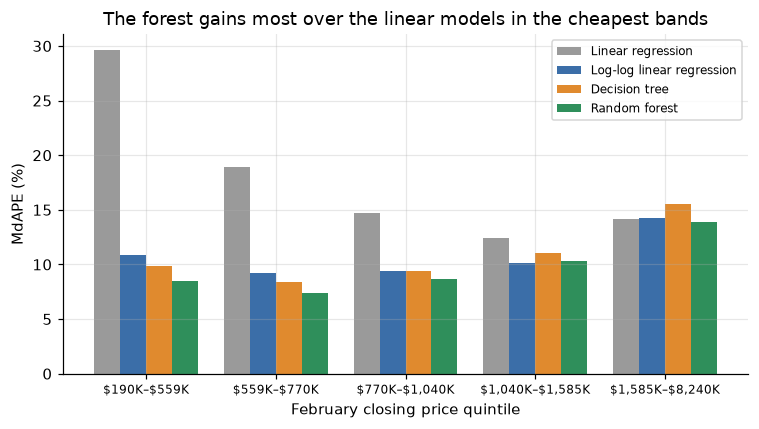

In [10]:
errors = avm.error_frame(val, MODEL_NAMES)
bands = pd.qcut(val["evaluate"].loc[in_range, TARGET], 5)
band_labels = {interval: f"${interval.left / 1e3:,.0f}K–${interval.right / 1e3:,.0f}K"
               for interval in bands.cat.categories}
errors["price_band"] = errors.index.map(bands).map(band_labels)

band_table = (errors.pivot_table(index="price_band", columns="model", sort=False,
                                 values=["APE_pct", "signed_pct"], aggfunc="median")
              .reindex(columns=MODEL_NAMES, level=1).loc[list(band_labels.values())])
band_counts = bands.value_counts().rename(index=band_labels).loc[band_table.index]
display(band_table.map("{:.1f}".format)
        .rename(columns={"APE_pct": "MdAPE (%)", "signed_pct": "Median bias (%)", **SHORT_NAMES})
        .set_index(band_counts.map("{:,}".format).rename("n"), append=True)
        .rename_axis(["Price band", "n"]))

fig, ax = plt.subplots()
width = 0.2
x = np.arange(len(band_labels))
for i, name in enumerate(MODEL_NAMES):
    ax.bar(x + (i - 1.5) * width, band_table[("APE_pct", name)], width,
           color=MODEL_COLORS[name], label=name)
# Escape "$" so matplotlib does not read the labels as math text.
ax.set_xticks(x, [label.replace("$", r"\$") for label in band_labels.values()], fontsize=8)
ax.set(xlabel="February closing price quintile", ylabel="MdAPE (%)", title="The forest gains most over the linear models in the cheapest bands")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The forest's largest advantage over log-log OLS is in the two cheapest bands (8.5% vs 10.8% under $559K, 7.4% vs 9.2% for $559K–$770K), where the Week 4 baseline was weakest (29.6%). From $1.04M to $1.59M the two are tied (10.3% vs 10.2%). Above $1.585M, MdAPE rises to 13.9–15.6% for every model, and the log-log, tree and forest models all under-predict by 8–9% at the median. The trees do not fix the top end.

In [11]:
city_volume = errors.query("model == @LINEAR")["City"].value_counts()
top_cities = city_volume[city_volume >= 30].head(15).index
city_table = (errors.query("City in @top_cities")
              .pivot_table(index="City", columns="model", values="APE_pct", aggfunc="median")
              [MODEL_NAMES].loc[top_cities])
city_table.insert(0, "n", city_volume.loc[top_cities])
city_table["Forest gain vs log-log"] = city_table[LOG_LINEAR] - city_table[FOREST]
print("February MdAPE (%) for the 15 highest-volume cities with at least 30 sales")
display(city_table.assign(n=city_table["n"].map("{:,}".format))
        .pipe(lambda t: t.assign(**{c: t[c].map("{:.1f}".format) for c in t.columns if c != "n"}))
        .rename(columns=SHORT_NAMES))

February MdAPE (%) for the 15 highest-volume cities with at least 30 sales


model,n,Linear,Log-log,Tree,Forest,Forest gain vs log-log
City,,,,,,
LOS ANGELES,378,19.4,16.6,17.3,15.3,1.3
SAN DIEGO,368,10.3,10.4,10.8,9.4,1.0
RIVERSIDE,142,25.2,9.1,7.3,6.1,2.9
SAN JOSE,129,13.8,12.2,9.5,10.4,1.7
MENIFEE,106,26.8,7.3,6.0,5.1,2.2
OAKLAND,105,20.9,15.7,17.4,15.1,0.5
OCEANSIDE,98,16.7,10.5,10.1,7.8,2.7
MURRIETA,97,22.2,10.6,7.4,5.8,4.7
LANCASTER,94,31.1,10.5,7.2,7.2,3.3


The forest beats or matches log-log OLS in all 15 cities. Its largest gains are in inland markets: Indio (5.6 points), Murrieta (4.7) and Moreno Valley (4.1). It is level in Long Beach (0.0) and San Bernardino (0.1). Los Angeles (15.3%) and Oakland (15.1%) remain the hardest large cities, likely because city and ZIP are too coarse where prices vary from block to block.

In [12]:
train_min, train_max = val["train_price_range"]
evaluate = val["evaluate"]
top_price = evaluate[TARGET] >= evaluate[TARGET].quantile(0.99)
top_size = evaluate["LivingArea"] >= evaluate["LivingArea"].quantile(0.99)

extrapolation = pd.DataFrame({
    name: {
        "Above training max": int((res["pred"] > train_max).sum()),
        "Below training min": int((res["pred"] < train_min).sum()),
        "Highest prediction ($)": res["pred"].max(),
        "Bias, top 1% by price (%)": 100 * ((res["pred"] - evaluate[TARGET]) / evaluate[TARGET])[top_price].median(),
        "Bias, top 1% by living area (%)": 100 * ((res["pred"] - evaluate[TARGET]) / evaluate[TARGET])[top_size].median(),
    }
    for name, res in val["results"].items()
}).T
print(f"Training prices ${train_min:,.0f}–${train_max:,.0f}; February sales up to "
      f"${evaluate[TARGET].max():,.0f}; {top_price.sum()} sales in the top 1% by price "
      f"(≥ ${evaluate.loc[top_price, TARGET].min():,.0f})")
display(extrapolation.assign(**{
    "Above training max": extrapolation["Above training max"].astype(int),
    "Below training min": extrapolation["Below training min"].astype(int),
    "Highest prediction ($)": extrapolation["Highest prediction ($)"].map("{:,.0f}".format),
    "Bias, top 1% by price (%)": extrapolation["Bias, top 1% by price (%)"].map("{:.1f}".format),
    "Bias, top 1% by living area (%)": extrapolation["Bias, top 1% by living area (%)"].map("{:.1f}".format),
}))

Training prices $190,000–$8,287,500; February sales up to $40,000,000; 90 sales in the top 1% by price (≥ $6,400,000)


,Above training max,Below training min,Highest prediction ($),"Bias, top 1% by price (%)","Bias, top 1% by living area (%)"
Linear regression,3,256,"9,462,236",-44.9,-23.6
Log-log linear regression,10,5,"13,641,083",-42.0,-25.1
Decision tree,0,0,"6,859,148",-42.9,-21.1
Random forest,0,0,"6,993,306",-40.9,-18.9


A tree predicts the average training price of the leaf a sale lands in, so it can never predict above the highest training price ($8.29M here) or below the lowest. Neither tree did. The linear models did: 256 linear predictions fall below $190K (30 of them negative), and log-log OLS predicts above $8.29M 10 times.

The cap is not what limits accuracy at the top, though. For the 90 sales of $6.4M or more, all four models under-predict by 41–45% at the median. For the largest 1% of homes by living area, they under-predict by 19–25%. The forest is the least biased in both groups, but no model trained on these six inputs can price February's $40M sale. This matters for an AVM that must value luxury homes that are not listed.

,Permutation: MdAPE increase (points),Std over repeats,Impurity share (%)
PostalCode,20.88,0.54,53.87
City,10.36,0.29,23.64
LivingArea,9.43,0.28,13.09
LotSizeSquareFeet,1.42,0.07,2.12
BathroomsTotalInteger,0.76,0.08,5.94
BedroomsTotal,0.59,0.10,1.35


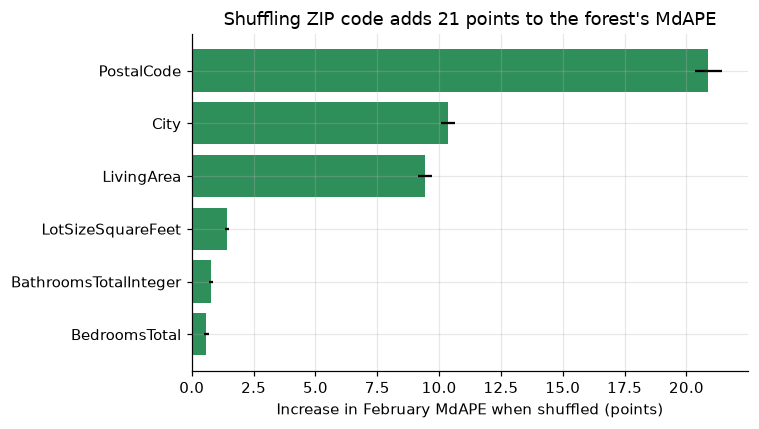

In [13]:
def mdape(y_true, y_pred):
    return 100 * np.median(np.abs(y_pred - y_true) / y_true)

sample = evaluate.loc[in_range].sample(IMPORTANCE_SAMPLE, random_state=RANDOM_STATE)
forest_model = val["results"][FOREST]["model"]
permutation = permutation_importance(
    forest_model, avm.model_inputs(sample), sample[TARGET], n_repeats=10,
    scoring=make_scorer(mdape, greater_is_better=False), random_state=RANDOM_STATE)

forest_pipeline = forest_model.regressor_ if hasattr(forest_model, "regressor_") else forest_model
transformed_names = forest_pipeline.named_steps["preprocess"].get_feature_names_out()
source_feature = [name.split("__")[1].replace("missingindicator_", "") for name in transformed_names]
impurity = (pd.Series(forest_pipeline.named_steps["regression"].feature_importances_, index=source_feature)
            .groupby(level=0).sum())

importance = pd.DataFrame({
    "Permutation: MdAPE increase (points)": permutation.importances_mean,
    "Std over repeats": permutation.importances_std,
}, index=avm.FEATURES)
importance["Impurity share (%)"] = 100 * impurity.reindex(avm.FEATURES)
importance = importance.sort_values("Permutation: MdAPE increase (points)")
display(importance.iloc[::-1].map("{:.2f}".format))

fig, ax = plt.subplots()
ax.barh(importance.index, importance["Permutation: MdAPE increase (points)"],
        xerr=importance["Std over repeats"], color=MODEL_COLORS[FOREST])
ax.set(xlabel="Increase in February MdAPE when shuffled (points)", title="Shuffling ZIP code adds 21 points to the forest's MdAPE")
plt.tight_layout()
plt.show()

Impurity importance credits each feature with the reduction in training squared error from the splits that use it. Features with many distinct values, like target-encoded ZIP and city, offer many candidate thresholds. They get picked for small splits that mostly fit noise in deep trees, so impurity importance overstates them. Permutation importance avoids this: it measures how much held-out February MdAPE worsens when one input is shuffled, here on a seeded 5,000-sale sample with 10 repeats.

Location dominates. Shuffling ZIP adds 20.9 points to MdAPE, city adds 10.4 and living area 9.4. Bedrooms (0.6) and bathrooms (0.8) add little once size and location are known. Impurity importance gives ZIP 54% of the credit and ranks bathrooms (5.9%) above lot size (2.1%), the reverse of the permutation ranking.

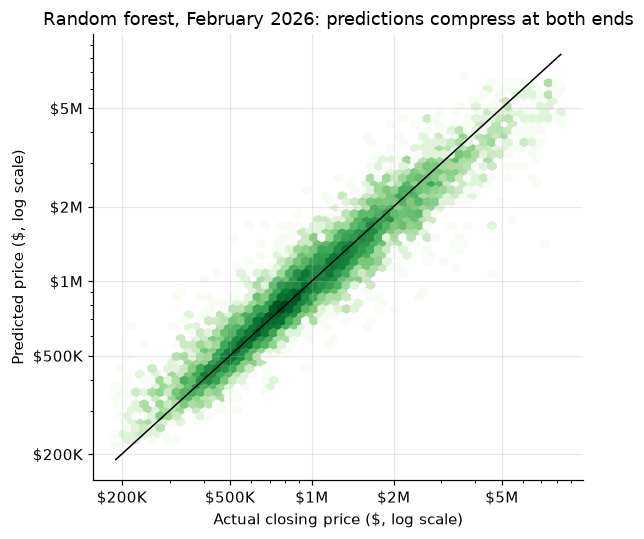

In [14]:
plot_data = errors.query("model == @best_tree")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.hexbin(plot_data["actual"], plot_data["prediction"], gridsize=55,
          xscale="log", yscale="log", bins="log", mincnt=1, cmap="Greens")
limits = [plot_data["actual"].min(), plot_data["actual"].max()]
ax.plot(limits, limits, color="black", linewidth=1)
ticks = [2e5, 5e5, 1e6, 2e6, 5e6]
dollars = FuncFormatter(lambda v, _: rf"\${v / 1e6:g}M" if v >= 1e6 else rf"\${v / 1e3:g}K")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_ticks(ticks)
    axis.set_major_formatter(dollars)
    axis.set_minor_formatter(NullFormatter())
ax.set(xlabel="Actual closing price ($, log scale)", ylabel="Predicted price ($, log scale)",
       title="Random forest, February 2026: predictions compress at both ends")
plt.tight_layout()
plt.show()

Most February sales fall close to the diagonal between about $300K and $3M. The cloud flattens at both ends, matching the band table: the cheapest sales are over-predicted (+3.6% median bias in the bottom quintile) and the most expensive under-predicted (−8.3% in the top quintile).

## 8. Final test: March 2026

March is scored once, after the February choices were locked in commit `61bcbdb`. `FINAL_CONFIGS` in section 5 is the frozen specification: each model is refit on every month before March (including February) with those exact settings and scored on March, filtered and all. Nothing was tuned on March, and the numbers are reported as they came out.

In [15]:
if RUN_FINAL_TEST:
    final = avm.run_cutoff(df, TEST_MONTH, final_factories, keep_models=True)
    runs[TEST_MONTH] = final
    print(f"March 2026, filtered (coverage {final['coverage']:.1%})")
    display(avm.format_table(avm.metrics_table(final, "filtered", SUMMARY_COLUMNS)))
    print("March 2026, all valid sales")
    display(avm.format_table(avm.metrics_table(final, "all", SUMMARY_COLUMNS)))
else:
    print("March 2026 held out. Set RUN_FINAL_TEST = True once the February choices are final.")

March 2026, filtered (coverage 98.8%)


,R²,MAE ($),RMSE ($),MAPE (%),MdAPE (%),Within 10% (%),Within 20% (%),Median bias (%),N
Linear regression,0.812,"238,462","410,446",22.6,16.6,32.7,57.8,-1.4,"11,420"
Log-log linear regression,0.826,"186,273","395,242",14.1,10.0,49.9,78.7,-1.3,"11,420"
Decision tree,0.838,"195,177","381,475",14.6,10.4,48.9,76.1,-0.7,"11,420"
Random forest,0.858,"178,544","356,816",13.2,9.2,53.2,79.8,-1.1,"11,420"


March 2026, all valid sales


,R²,MAE ($),RMSE ($),MAPE (%),MdAPE (%),Within 10% (%),Within 20% (%),Median bias (%),N
Linear regression,0.632,"288,654","893,730",23.7,16.9,32.3,57.1,-1.5,"11,560"
Log-log linear regression,0.698,"230,358","809,225",15.3,10.2,49.3,77.8,-1.3,"11,560"
Decision tree,0.608,"247,356","921,964",16.0,10.5,48.3,75.2,-0.7,"11,560"
Random forest,0.628,"229,933","898,351",14.6,9.3,52.6,78.9,-1.1,"11,560"


## 9. Save metrics and the selected model

`model_comparison_metrics.csv` uses the same schema as `baseline_metrics.csv`, with RMSE and a `params` column added; the linear rows are produced by the same code as the trees rather than copied from Week 4, and they match the Week 4 March figures. The best tree pipeline is saved with its feature list for the Week 9 app. Because the final test has run, the saved model is the forest refit on every month through February 2026, the version the Week 9 app should load.

In [16]:
model_comparison = pd.concat([
    backtest_metrics,
    pd.DataFrame([row for run in runs.values() for row in avm.metric_records(run, PARAMS)]),
], ignore_index=True)
model_comparison.to_csv(RESULTS_DIR / "model_comparison_metrics.csv", index=False)

# The saved model is the one the latest scored split was trained for.
source = runs[TEST_MONTH] if RUN_FINAL_TEST else val
fitted = source["results"][best_tree]["model"]
bundle = {"model": fitted, "model_name": best_tree, "params": PARAMS[best_tree],
          "features": avm.FEATURES, "numeric": avm.NUMERIC, "categorical": avm.CATEGORICAL,
          "trained_months": source["train_months"],
          "price_bounds": (source["lower"], source["upper"]),
          "data_snapshot": fingerprint, "sklearn_version": sklearn.__version__}
MODELS_DIR.mkdir(exist_ok=True)
model_path = MODELS_DIR / "best_tree_model.joblib"
joblib.dump(bundle, model_path, compress=3)
(MODELS_DIR / "feature_list.json").write_text(json.dumps(avm.FEATURES, indent=2))

# Round-trip check, the same one the Week 9 app should run before predicting.
loaded = joblib.load(model_path)
assert list(loaded["model"].feature_names_in_) == loaded["features"]
sample_x = avm.model_inputs(source["evaluate"].head(200))
assert np.allclose(loaded["model"].predict(sample_x), fitted.predict(sample_x))

print("Saved", len(model_comparison), "rows to", RESULTS_DIR / "model_comparison_metrics.csv")
print(f"Saved {best_tree} ({PARAMS[best_tree]}), trained {bundle['trained_months'][0]}–"
      f"{bundle['trained_months'][1]}, to {model_path} ({model_path.stat().st_size / 1e6:,.0f} MB)")

Saved 40 rows to ../results/model_comparison_metrics.csv
Saved Random forest (n_estimators=200, max_features=0.5, min_samples_leaf=5, max_depth=None, target=log price), trained 202401–202602, to ../models/best_tree_model.joblib (256 MB)


## 10. Results and notes

Numbers below are copied from the executed outputs above (snapshot `2ff3877a04bd`, 297,152 sales after cleaning). "Filtered" means sales within the training-derived 0.5th–99.5th percentile price bounds ($190,000–$8,287,751 for February).

**February 2026 validation** (filtered, N = 8,869, coverage 99.0%)

| Model | R² | MAE ($) | RMSE ($) | MAPE (%) | MdAPE (%) | Within 10% | Within 20% |
|---|---:|---:|---:|---:|---:|---:|---:|
| Linear regression (baseline) | 0.811 | 247,365 | 425,290 | 23.3 | 16.8 | 31.1% | 57.5% |
| Log-log linear regression | 0.832 | 193,244 | 400,938 | 14.7 | 10.6 | 47.8% | 76.9% |
| Decision tree | 0.834 | 199,599 | 398,383 | 15.1 | 10.6 | 48.2% | 74.8% |
| Random forest | 0.859 | 181,860 | 367,288 | 13.7 | **9.5** | 52.0% | 78.5% |

**Rolling-origin MdAPE (%)**, filtered

| Model | 2025-11 | 2025-12 | 2026-01 | 2026-02 |
|---|---:|---:|---:|---:|
| Linear regression | 16.5 | 16.8 | 17.1 | 16.8 |
| Log-log linear regression | 10.0 | 10.1 | 10.6 | 10.6 |
| Decision tree | 10.3 | 10.4 | 10.3 | 10.6 |
| Random forest | 9.3 | 9.3 | 9.3 | 9.5 |

**March 2026 test** (scored once with the configurations frozen in `FINAL_CONFIGS`; refit on all months through February; coverage 98.8%)

| Model | Scope | R² | MAE ($) | MdAPE (%) | Within 10% | Within 20% | N |
|---|---|---:|---:|---:|---:|---:|---:|
| Linear regression (baseline) | filtered | 0.812 | 238,462 | 16.6 | 32.7% | 57.8% | 11,420 |
| Log-log linear regression | filtered | 0.826 | 186,273 | 10.0 | 49.9% | 78.7% | 11,420 |
| Decision tree | filtered | 0.838 | 195,177 | 10.4 | 48.9% | 76.1% | 11,420 |
| Random forest | filtered | 0.858 | 178,544 | **9.2** | 53.2% | 79.8% | 11,420 |
| Linear regression (baseline) | all | 0.632 | 288,654 | 16.9 | 32.3% | 57.1% | 11,560 |
| Log-log linear regression | all | 0.698 | 230,358 | 10.2 | 49.3% | 77.8% | 11,560 |
| Decision tree | all | 0.608 | 247,356 | 10.5 | 48.3% | 75.2% | 11,560 |
| Random forest | all | 0.628 | 229,933 | 9.3 | 52.6% | 78.9% | 11,560 |

The forest has the lowest March MdAPE in both scopes, consistent with the backtests (9.3–9.5%). Its margin over log-log OLS is smaller than in February (0.86 points vs 1.12); the February bootstrap interval was 0.88 to 1.40, so the March gap sits just below it. No March bootstrap was run, so whether the narrower margin is noise or a real shift is not established here. The single tree is worse than log-log OLS in March (10.4% vs 10.0%), unlike February, which supports treating it as no better than the linear reference. On all sales the trees' R² falls below log-log OLS (0.628 forest, 0.608 tree, 0.698 log-log) because they cannot predict above the training price range.

**Strengths and weaknesses**

- **Overfitting and variance.** A single tree overfits easily. Unrestricted, it fits its training sales to 1.0% MdAPE and scores 12.6% in February, and it needed at least 50 sales per leaf to match log-log OLS. The forest also fits training sales better than new ones (7.4% vs 9.5%), but averaging removes most of that variance: it had the best February score and a 0.2-point spread across cutoffs. The linear models have low variance (0.9-point gap) and high bias.
- **Extrapolation.** Neither tree can predict outside the training price range ($190K–$8.29M). This prevents absurd predictions (the raw linear model made 30 negative ones) but caps luxury values. All four models under-predict the top 1% of February sales by 41–45%, so the cap is one problem among several at the top end, not the main one.
- **Interpretability.** Linear coefficients can be read directly. A depth-18 tree with up to 5,478 leaves (273,904 sales / 50) is technically a set of rules but not readable in practice. The forest needs post-hoc tools such as the permutation importance above.
- **Nonlinearity and interactions.** Trees pick up location-by-size interactions without manual terms. The forest's largest gains over log-log OLS are in the cheapest price bands and inland cities, where a single statewide slope for living area fits worst. The linear models need the log-log transform to approximate this.
- **Training cost.** Each linear fit takes about 2 seconds and a tree under 1 second. The selected forest takes about 14 seconds per fit and saves as a 248 MB file. The full forest grid took about 18 minutes, most of it on the 400-tree, no-leaf-limit configurations, which also caused the memory problems that motivated the tolerance rule.

**Assumptions and limitations**

- Model selection used one validation month. The backtests confirm the ranking, but configurations were not re-tuned at each cutoff.
- The 0.1-point tolerance in the selection rule was introduced after seeing the first grid results, to avoid a 2.2 GB model that is only 0.03 points better. It was decided on February evidence and memory cost alone; March was not consulted.
- Training-set scores use the target encoder's full-data encodings, not the cross-fitted ones used in fitting, so the train-vs-validation gaps are approximate.
- Rare ZIPs and cities are shrunk toward the overall training mean by the encoder's smoothing, and categories first seen in the evaluation month receive that mean.
- Including sales outside the price bounds, the forest's R² (0.683) is below log-log OLS (0.711), because trees cannot extrapolate to the few very expensive sales.
- The Week 4 limitations still apply: only sold properties are observed, location is city and ZIP only, and property condition and renovation history are not available.

**Reproducibility.** `RANDOM_STATE = 42` seeds every tree and forest, the target encoder's folds, the bootstrap and the importance sample. Results do not depend on `n_jobs`. The data snapshot is `2ff3877a04bd` (per-file hashes in `results/data_snapshot.csv`). Versions: pandas 3.0.6, numpy 2.5.3, scikit-learn 1.9.1, joblib 1.6.0, all pinned in `requirements.txt`; no new packages were needed. Shared code is in `src/avm.py`. Outputs: `results/model_comparison_metrics.csv`, `results/tuning_grid.csv`, `models/best_tree_model.joblib` and `models/feature_list.json`.

**Next steps**

- Week 6: add property age at sale, a bed/bath ratio, and a school-district layer from a spatial join of latitude/longitude against the CA School District Areas 2024–25 boundaries. Finer location is the most likely fix for Los Angeles and Oakland, given how much the forest relies on ZIP.
- Week 7: try gradient boosting (LightGBM or XGBoost) on the same pipeline, tuned on February, and compare it to the forest with the same paired bootstrap.